In [490]:
import gc

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import KFold, train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import OneHotEncoder
import statsmodels.api as sm

DATA_DIR = '~/github/reddit-sentiment-analysis/data'

# 1. Read data and generate fields

In [491]:
# read and combine dataframes
df_posts = pd.read_parquet(f'{DATA_DIR}/posts.parquet.brotli', engine='pyarrow')
df_comments = pd.read_parquet(f'{DATA_DIR}/comments.parquet.brotli', engine='pyarrow')
df_comment_sentiments = pd.read_csv(f'{DATA_DIR}/roberta_comment_sentiments.csv')
df_title_sentiments = pd.read_csv(f'{DATA_DIR}/roberta_post_title_sentiments.csv')

df_comments = pd.merge(left=df_comments,
                       right=df_comment_sentiments,
                       on='comment_id',
                       how='left')
del df_comment_sentiments
gc.collect()

df_posts = pd.merge(left=df_posts, 
                    right=df_title_sentiments,
                    on='post_id',
                    how='left')
df_posts = df_posts.drop(columns=['sentiment_score'])
df_posts.rename(columns={'sentiment': 'title_sentiment'}, inplace=True)
del df_title_sentiments
gc.collect()

0

In [492]:
# calculate the average sentiment of all comments for a single post
# the sentiment for each single comment is weighted by its sentiment score, 
# i.e. how confident the model is for the predicted sentiment
df_avg_comment_sentiments = df_comments.groupby(by='post_id').apply(lambda df: (df['sentiment'] * df['sentiment_score']).mean())
df_avg_comment_sentiments = df_avg_comment_sentiments.reset_index()
df_avg_comment_sentiments = df_avg_comment_sentiments.rename(columns={0: 'avg_comment_sentiment'})

df_posts = pd.merge(left=df_posts,
                    right=df_avg_comment_sentiments,
                    on='post_id',
                    how='left')
del df_avg_comment_sentiments
gc.collect()

/var/folders/xs/8150jdld2zl47ndf914xvw840000gn/T/ipykernel_67938/3413049870.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_avg_comment_sentiments = df_comments.groupby(by='post_id').apply(lambda df: (df['sentiment'] * df['sentiment_score']).mean())


0

In [493]:
df_posts.info()
df_posts.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4135 entries, 0 to 4134
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   post_id                4135 non-null   object        
 1   subreddit              4135 non-null   category      
 2   title                  4135 non-null   string        
 3   flair                  2453 non-null   string        
 4   score                  4135 non-null   int64         
 5   creation_time          4135 non-null   datetime64[ns]
 6   number_of_comments     4135 non-null   int64         
 7   upvote_ratio           4135 non-null   float64       
 8   title_sentiment        4135 non-null   int64         
 9   avg_comment_sentiment  4099 non-null   float64       
dtypes: category(1), datetime64[ns](1), float64(2), int64(3), object(1), string(2)
memory usage: 295.3+ KB


,post_id,subreddit,title,flair,score,creation_time,number_of_comments,upvote_ratio,title_sentiment,avg_comment_sentiment
0,1501ibb,AskReddit,"What Worst possible reply to ""I'm pregnant""?",<NA>,11202,2023-07-15 04:06:56,12625,0.85,-1,-0.100117
1,14zz798,AskReddit,What is a personal story you have that you don...,<NA>,6607,2023-07-15 02:12:11,2891,0.97,0,-0.129171
2,14zx7iq,AskReddit,How did that person in your class become rich?,<NA>,4251,2023-07-15 00:38:28,2542,0.94,-1,0.004528
3,150aarj,AskReddit,What is the worst reply to “I’m leaving you”?,<NA>,3608,2023-07-15 12:03:43,3564,0.89,-1,-0.116651
4,150j9g1,AskReddit,Who's the Most Dangerous Human Alive Right Now?,<NA>,2287,2023-07-15 18:28:51,3389,0.66,-1,-0.254715


In [494]:
df_posts.describe()

,score,creation_time,number_of_comments,upvote_ratio,title_sentiment,avg_comment_sentiment
count,4135.000000,4135,4135.000000,4135.000000,4135.000000,4099.000000
mean,3918.319952,2024-04-13 11:11:40.344619008,719.895042,0.904068,-0.173398,-0.137828
min,0.000000,2023-07-15 00:03:22,0.000000,0.210000,-1.000000,-0.943186
25%,312.000000,2023-07-25 07:44:09,51.000000,0.880000,-1.000000,-0.330219
50%,1164.000000,2024-10-22 20:01:50,182.000000,0.920000,0.000000,-0.173017
75%,4059.000000,2024-11-02 18:13:20.500000,614.500000,0.960000,0.000000,0.011019
max,74673.000000,2024-11-13 05:28:35,58240.000000,1.000000,1.000000,0.988485
std,7026.443440,NaN,1823.082222,0.073852,0.618352,0.261238


In [495]:
# remove the post with zero score and zero number of comments
print((df_posts['score'] == 0).sum())
print((df_posts['number_of_comments'] == 0).sum())
zero_idx = (df_posts['score'] == 0) | (df_posts['number_of_comments'] == 0)

df_posts = df_posts.loc[~zero_idx].reset_index(drop=True)

# df_posts = df_posts.loc[~zero_idx]
# df_posts.describe()
df_posts.info()

10
32
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4094 entries, 0 to 4093
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   post_id                4094 non-null   object        
 1   subreddit              4094 non-null   category      
 2   title                  4094 non-null   string        
 3   flair                  2434 non-null   string        
 4   score                  4094 non-null   int64         
 5   creation_time          4094 non-null   datetime64[ns]
 6   number_of_comments     4094 non-null   int64         
 7   upvote_ratio           4094 non-null   float64       
 8   title_sentiment        4094 non-null   int64         
 9   avg_comment_sentiment  4089 non-null   float64       
dtypes: category(1), datetime64[ns](1), float64(2), int64(3), object(1), string(2)
memory usage: 292.4+ KB


In [496]:
# handle the missing values
df_posts['avg_comment_sentiment'] = df_posts['avg_comment_sentiment'].fillna(df_posts['avg_comment_sentiment'].mean())

In [497]:
# One-hot encode the 'subreddit' field
encoder = OneHotEncoder(drop='first', sparse_output=False)
subreddit_encoded = encoder.fit_transform(df_posts[['subreddit']])
subreddit_encoded_df = pd.DataFrame(subreddit_encoded, columns=encoder.get_feature_names_out())

df_posts = pd.concat([df_posts, subreddit_encoded_df], axis=1)

In [498]:
# log transform std_score, std_number_of_comments
for field in ['score', 'number_of_comments']:
    df_posts['log_' + field] = np.log(df_posts[field])

df_posts.head()

,post_id,subreddit,title,flair,score,creation_time,number_of_comments,upvote_ratio,title_sentiment,avg_comment_sentiment,...,subreddit_explainlikeimfive,subreddit_gaming,subreddit_movies,subreddit_politics,subreddit_science,subreddit_sports,subreddit_technology,subreddit_worldnews,log_score,log_number_of_comments
0,1501ibb,AskReddit,"What Worst possible reply to ""I'm pregnant""?",<NA>,11202,2023-07-15 04:06:56,12625,0.85,-1,-0.100117,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,9.323848,9.443434
1,14zz798,AskReddit,What is a personal story you have that you don...,<NA>,6607,2023-07-15 02:12:11,2891,0.97,0,-0.129171,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.795885,7.969358
2,14zx7iq,AskReddit,How did that person in your class become rich?,<NA>,4251,2023-07-15 00:38:28,2542,0.94,-1,0.004528,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.354910,7.840706
3,150aarj,AskReddit,What is the worst reply to “I’m leaving you”?,<NA>,3608,2023-07-15 12:03:43,3564,0.89,-1,-0.116651,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.190909,8.178639
4,150j9g1,AskReddit,Who's the Most Dangerous Human Alive Right Now?,<NA>,2287,2023-07-15 18:28:51,3389,0.66,-1,-0.254715,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,7.734996,8.128290


In [499]:
df_posts.describe()

,score,creation_time,number_of_comments,upvote_ratio,title_sentiment,avg_comment_sentiment,subreddit_books,subreddit_explainlikeimfive,subreddit_gaming,subreddit_movies,subreddit_politics,subreddit_science,subreddit_sports,subreddit_technology,subreddit_worldnews,log_score,log_number_of_comments
count,4094.000000,4094,4094.000000,4094.000000,4094.000000,4094.000000,4094.000000,4094.000000,4094.000000,4094.000000,4094.000000,4094.000000,4094.000000,4094.000000,4094.000000,4094.000000,4094.000000
mean,3957.241573,2024-04-14 01:08:36.939667968,727.047875,0.906033,-0.175623,-0.137943,0.093063,0.102101,0.101856,0.101368,0.101368,0.101856,0.094529,0.100635,0.101856,6.959507,5.182688
min,1.000000,2023-07-15 00:03:22,1.000000,0.520000,-1.000000,-0.943186,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,330.000000,2023-07-25 07:27:07.500000,54.000000,0.880000,-1.000000,-0.330243,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.799093,3.988984
50%,1196.000000,2024-10-22 20:32:41,185.000000,0.930000,0.000000,-0.172916,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.086738,5.220356
75%,4114.500000,2024-11-02 18:13:24.750000128,624.750000,0.960000,0.000000,0.010851,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.322272,6.437351
max,74673.000000,2024-11-13 05:28:35,58240.000000,1.000000,1.000000,0.988485,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,11.220874,10.972328
std,7050.713391,NaN,1830.780954,0.068830,0.619089,0.260951,0.290556,0.302818,0.302496,0.301852,0.301852,0.302496,0.292598,0.300882,0.302496,1.879393,1.815553


In [500]:
df_posts.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4094 entries, 0 to 4093
Data columns (total 21 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   post_id                      4094 non-null   object        
 1   subreddit                    4094 non-null   category      
 2   title                        4094 non-null   string        
 3   flair                        2434 non-null   string        
 4   score                        4094 non-null   int64         
 5   creation_time                4094 non-null   datetime64[ns]
 6   number_of_comments           4094 non-null   int64         
 7   upvote_ratio                 4094 non-null   float64       
 8   title_sentiment              4094 non-null   int64         
 9   avg_comment_sentiment        4094 non-null   float64       
 10  subreddit_books              4094 non-null   float64       
 11  subreddit_explainlikeimfive  4094 non-null 

In [501]:
# get the features and target
FEATURES = ['log_number_of_comments',
              'upvote_ratio',
              'title_sentiment',
              'avg_comment_sentiment',
              ] + encoder.get_feature_names_out().tolist()
TARGET = 'log_score'

In [502]:
(df_posts[FEATURES] == -np.inf).sum()
(df_posts[TARGET] == np.inf).sum()

df_posts[FEATURES].describe()
df_posts[TARGET].min()
df_posts[TARGET].max()

11.220873860000504

# 2.  EDA

<Axes: xlabel='title_sentiment', ylabel='log_score'>

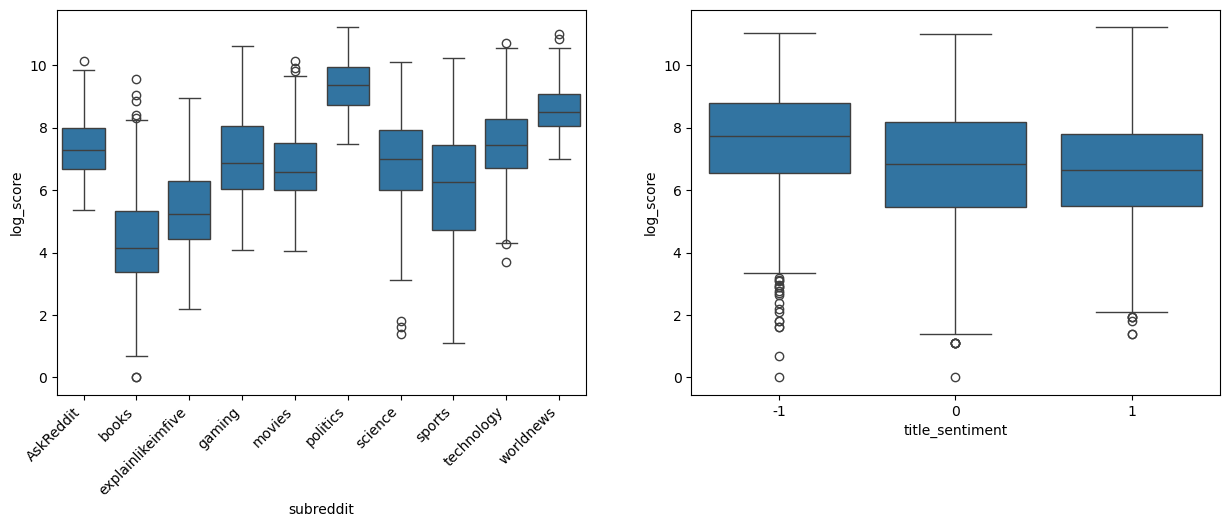

In [503]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 5))
sns.boxplot(data=df_posts, x='subreddit', y='log_score', ax=axes[0])
axes[0].set_xticks(axes[0].get_xticks(), axes[0].get_xticklabels(), rotation=45, ha='right')
sns.boxplot(data=df_posts, x='title_sentiment', y='log_score', ax=axes[1])

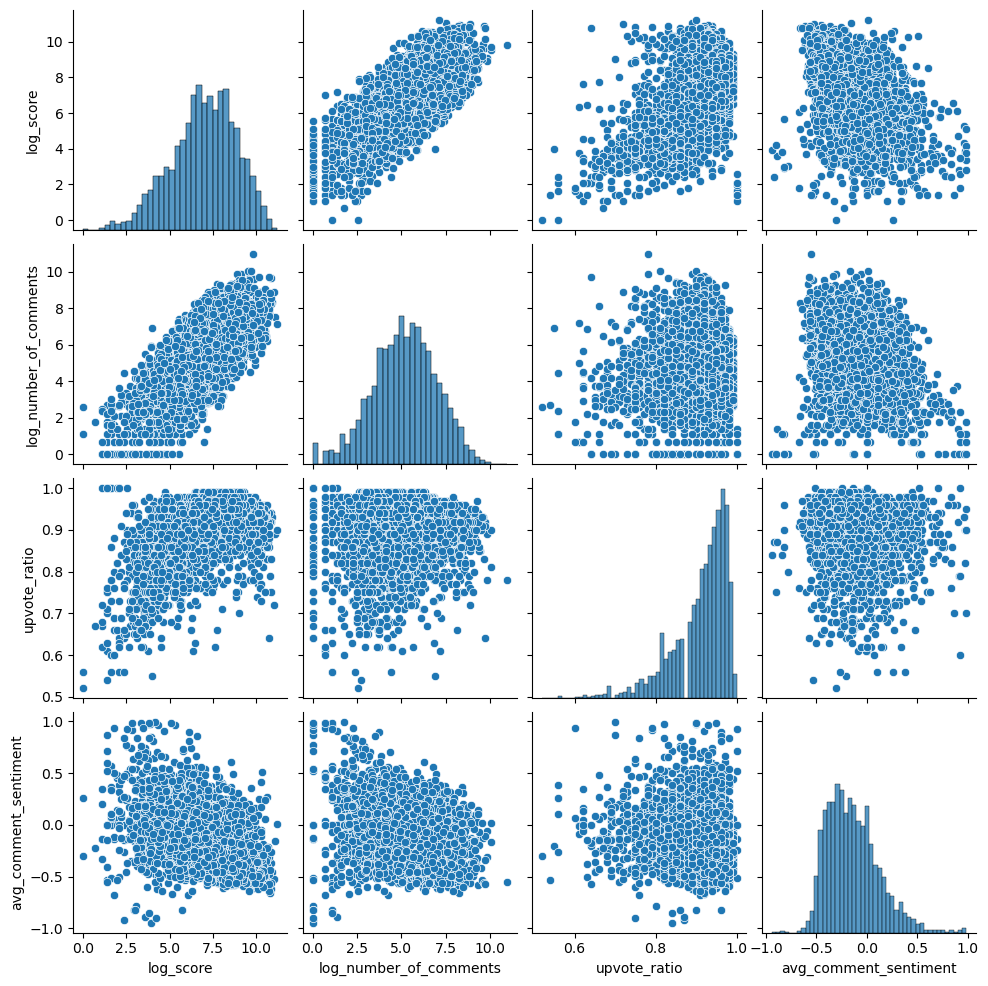

In [504]:
sns.pairplot(data=df_posts[['log_score', 'log_number_of_comments', 'upvote_ratio', 'avg_comment_sentiment']])


# Linear Regression

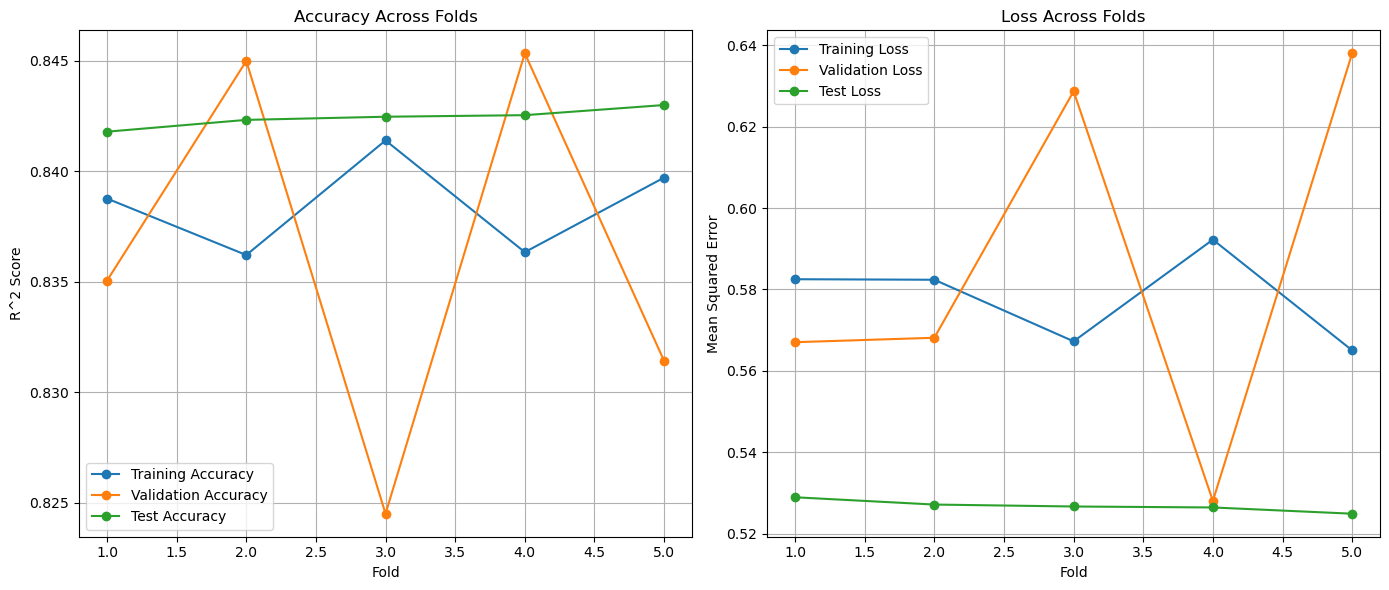

In [505]:
X = df_posts[FEATURES]
y = df_posts[TARGET]

# Split the data into train and test sets
X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize k-fold cross-validation
k = 5
kf = KFold(n_splits=k, shuffle=True, random_state=42)

# Initialize lists to store metrics
train_accuracies = []
val_accuracies = []
test_accuracies = []

train_losses = []
val_losses = []
test_losses = []

# Initialize the model
model = LinearRegression()

# Perform k-fold cross-validation
for train_index, val_index in kf.split(X_train_full):
    X_train, X_val = X_train_full.iloc[train_index], X_train_full.iloc[val_index]
    y_train, y_val = y_train_full.iloc[train_index], y_train_full.iloc[val_index]

    # Train the model
    model.fit(X_train, y_train)

    # Predict on training, validation, and test sets
    y_train_pred = model.predict(X_train)
    y_val_pred = model.predict(X_val)
    y_test_pred = model.predict(X_test)

    # Calculate R^2 scores (accuracy)
    train_accuracies.append(r2_score(y_train, y_train_pred))
    val_accuracies.append(r2_score(y_val, y_val_pred))
    test_accuracies.append(r2_score(y_test, y_test_pred))

    # Calculate Mean Squared Errors (loss)
    train_losses.append(mean_squared_error(y_train, y_train_pred))
    val_losses.append(mean_squared_error(y_val, y_val_pred))
    test_losses.append(mean_squared_error(y_test, y_test_pred))

# Plot the accuracies and losses
folds = np.arange(1, k + 1)

plt.figure(figsize=(14, 6))

# Plot R^2 scores
plt.subplot(1, 2, 1)
plt.plot(folds, train_accuracies, label='Training Accuracy', marker='o')
plt.plot(folds, val_accuracies, label='Validation Accuracy', marker='o')
plt.plot(folds, test_accuracies, label='Test Accuracy', marker='o')
plt.xlabel('Fold')
plt.ylabel('R^2 Score')
plt.title('Accuracy Across Folds')
plt.legend()
plt.grid()

# Plot Mean Squared Errors
plt.subplot(1, 2, 2)
plt.plot(folds, train_losses, label='Training Loss', marker='o')
plt.plot(folds, val_losses, label='Validation Loss', marker='o')
plt.plot(folds, test_losses, label='Test Loss', marker='o')
plt.xlabel('Fold')
plt.ylabel('Mean Squared Error')
plt.title('Loss Across Folds')
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

# Linear regression with OLS

In [506]:
X = df_posts[FEATURES]
y = df_posts[TARGET]

# Add a constant to the model (for the intercept)
X = sm.add_constant(X)

# Split the data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3275 entries, 2466 to 3174
Data columns (total 14 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   const                        3275 non-null   float64
 1   log_number_of_comments       3275 non-null   float64
 2   upvote_ratio                 3275 non-null   float64
 3   title_sentiment              3275 non-null   int64  
 4   avg_comment_sentiment        3275 non-null   float64
 5   subreddit_books              3275 non-null   float64
 6   subreddit_explainlikeimfive  3275 non-null   float64
 7   subreddit_gaming             3275 non-null   float64
 8   subreddit_movies             3275 non-null   float64
 9   subreddit_politics           3275 non-null   float64
 10  subreddit_science            3275 non-null   float64
 11  subreddit_sports             3275 non-null   float64
 12  subreddit_technology         3275 non-null   float64
 13  subreddit_worldnews 

In [507]:


# Fit the model using OLS
ols_model = sm.OLS(y_train, X_train).fit()

# Print the summary of the model
# print(ols_model.summary())
ols_model.summary()

# # Predict on the test set
# y_test_pred = ols_model.predict(X_test)

# # Plot the actual vs predicted values
# plt.figure(figsize=(8, 6))
# plt.scatter(y_test, y_test_pred, alpha=0.6, color='b')
# plt.xlabel('Actual Values')
# plt.ylabel('Predicted Values')
# plt.title('Actual vs Predicted Values')
# plt.grid()
# plt.show()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:              log_score   R-squared:                       0.838
Model:                            OLS   Adj. R-squared:                  0.838
Method:                 Least Squares   F-statistic:                     1300.
Date:                Mon, 25 Nov 2024   Prob (F-statistic):               0.00
Time:                        21:03:11   Log-Likelihood:                -3751.4
No. Observations:                3275   AIC:                             7531.
Df Residuals:                    3261   BIC:                             7616.
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
===============================================================================================
                                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
const                          -5.1732      0.223    -23.246      0.000      -5.610      -4.737
log_number_of_comments          0.7046      0.010     67.291      0.000       0.684       0.725
upvote_ratio                    7.8756      0.227     34.717      0.000       7.431       8.320
title_sentiment                 0.0858      0.024      3.514      0.000       0.038       0.134
avg_comment_sentiment          -0.2214      0.071     -3.126      0.002      -0.360      -0.083
subreddit_books                 0.2032      0.074      2.752      0.006       0.058       0.348
subreddit_explainlikeimfive     0.8371      0.070     12.041      0.000       0.701       0.973
subreddit_gaming                1.5010      0.064     23.284      0.000       1.375       1.627
subreddit_movies                1.1644      0.064     18.212      0.000       1.039       1.290
subreddit_politics              2.2573      0.064     35.036      0.000       2.131       2.384
subreddit_science               1.8538      0.072     25.724      0.000       1.713       1.995
subreddit_sports                1.5548      0.074     20.998      0.000       1.410       1.700
subreddit_technology            1.7931      0.068     26.445      0.000       1.660       1.926
subreddit_worldnews             2.1103      0.066     31.966      0.000       1.981       2.240
==============================================================================
Omnibus:                       49.870   Durbin-Watson:                   2.039
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               92.167
Skew:                          -0.046   Prob(JB):                     9.69e-21
Kurtosis:                       3.817   Cond. No.                         134.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""